# 01 - Exploratory Data Analysis (EDA)

**Progetto:** Credit Risk Scorecard - *Give Me Some Credit* (Kaggle)

Obiettivo di questo notebook:

1. Caricare il dataset grezzo `cs-training.csv`
2. Fare una panoramica generale (dimensioni, tipi, missing, statistiche descrittive)
3. Analizzare la distribuzione della variabile target `SeriousDlqin2yrs`
4. Gestire i valori mancanti (`MonthlyIncome`, `NumberOfDependents`)
5. Individuare e trattare gli outlier noti del dataset (età, valori sentinella 96/98, code estreme di `RevolvingUtilizationOfUnsecuredLines` e `DebtRatio`)
6. Salvare il dataset pulito in `data/processed/` per i notebook successivi

Ogni decisione di pulizia è motivata con i numeri effettivamente osservati sui dati, non con regole generiche.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)

# Palette del progetto (blu sequenziale + coppia good/critical per la variabile target)
COLOR_GOOD = '#0ca30c'
COLOR_CRITICAL = '#d03b3b'
COLOR_SEQ = '#2a78d6'
GRID_COLOR = '#e1e0d9'
TEXT_COLOR = '#0b0b0b'
MUTED_COLOR = '#898781'

plt.rcParams.update({
    'figure.facecolor': '#fcfcfb',
    'axes.facecolor': '#fcfcfb',
    'axes.edgecolor': GRID_COLOR,
    'axes.grid': True,
    'grid.color': GRID_COLOR,
    'grid.linewidth': 0.8,
    'axes.axisbelow': True,
    'text.color': TEXT_COLOR,
    'axes.labelcolor': TEXT_COLOR,
    'xtick.color': MUTED_COLOR,
    'ytick.color': MUTED_COLOR,
    'font.size': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

## 1. Caricamento dataset

La prima colonna del CSV non ha un nome (è un identificativo progressivo di riga, da 1 a 150000):
la carichiamo esplicitamente come indice del DataFrame con `index_col=0`, invece di lasciarla
come colonna "Unnamed: 0".

In [2]:
# Percorsi relativi al progetto (il notebook vive in notebooks/01_eda/)
PROJECT_ROOT = Path.cwd().resolve().parents[1]
RAW_PATH = PROJECT_ROOT / 'data' / 'raw' / 'cs-training.csv'
PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
PROCESSED_PATH = PROCESSED_DIR / 'cs-training-clean.csv'

df = pd.read_csv(RAW_PATH, index_col=0)
df.index.name = 'id'

print(f"File caricato da: {RAW_PATH.relative_to(PROJECT_ROOT).as_posix()}")
df.head()

File caricato da: data/raw/cs-training.csv


## 2. Panoramica generale

In [3]:
print(f"Numero di righe: {df.shape[0]:,}")
print(f"Numero di colonne: {df.shape[1]}")
print()
df.dtypes

Numero di righe: 150,000
Numero di colonne: 11



SeriousDlqin2yrs                          int64
RevolvingUtilizationOfUnsecuredLines    float64
age                                       int64
NumberOfTime30-59DaysPastDueNotWorse      int64
DebtRatio                               float64
MonthlyIncome                           float64
NumberOfOpenCreditLinesAndLoans           int64
NumberOfTimes90DaysLate                   int64
NumberRealEstateLoansOrLines              int64
NumberOfTime60-89DaysPastDueNotWorse      int64
NumberOfDependents                      float64
dtype: object

In [4]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
overview = pd.DataFrame({'missing': missing, 'missing_%': missing_pct})
overview[overview['missing'] > 0].sort_values('missing', ascending=False)

,missing,missing_%
MonthlyIncome,29731,19.82
NumberOfDependents,3924,2.62


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
SeriousDlqin2yrs,150000.0,0.066840,0.249746,0.0,0.000000,0.000000,0.000000,1.0
RevolvingUtilizationOfUnsecuredLines,150000.0,6.048438,249.755371,0.0,0.029867,0.154181,0.559046,50708.0
age,150000.0,52.295207,14.771866,0.0,41.000000,52.000000,63.000000,109.0
NumberOfTime30-59DaysPastDueNotWorse,150000.0,0.421033,4.192781,0.0,0.000000,0.000000,0.000000,98.0
DebtRatio,150000.0,353.005076,2037.818523,0.0,0.175074,0.366508,0.868254,329664.0
MonthlyIncome,120269.0,6670.221237,14384.674215,0.0,3400.000000,5400.000000,8249.000000,3008750.0
NumberOfOpenCreditLinesAndLoans,150000.0,8.452760,5.145951,0.0,5.000000,8.000000,11.000000,58.0
NumberOfTimes90DaysLate,150000.0,0.265973,4.169304,0.0,0.000000,0.000000,0.000000,98.0
NumberRealEstateLoansOrLines,150000.0,1.018240,1.129771,0.0,0.000000,1.000000,2.000000,54.0
NumberOfTime60-89DaysPastDueNotWorse,150000.0,0.240387,4.155179,0.0,0.000000,0.000000,0.000000,98.0


In [6]:
n_dup = df.duplicated().sum()
print(f"Righe duplicate (tutte le colonne uguali, indice escluso): {n_dup} ({n_dup / len(df) * 100:.2f}%)")

Righe duplicate (tutte le colonne uguali, indice escluso): 609 (0.41%)


**Nota sui duplicati:** con diverse colonne intere a bassa cardinalità (es. `NumberOfDependents`,
`NumberOfOpenCreditLinesAndLoans`) su 150.000 righe è statisticamente plausibile che alcuni profili
coincidano per caso. Non avendo un identificativo cliente né evidenza che si tratti di errori di
caricamento, non li rimuoviamo in questa fase: la scelta viene lasciata a un'eventuale analisi
successiva (es. in fase di train/test split, per evitare che lo stesso profilo compaia in entrambi i set).

## 3. Distribuzione della variabile target (`SeriousDlqin2yrs`)

SeriousDlqin2yrs
0    139974
1     10026
Name: count, dtype: int64

SeriousDlqin2yrs
0    93.32 %
1     6.68 %
Name: proportion, dtype: str


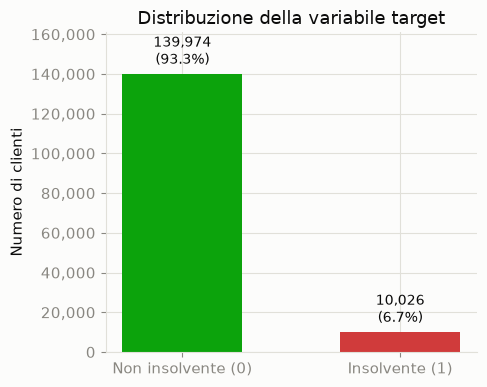

In [7]:
target_counts = df['SeriousDlqin2yrs'].value_counts().sort_index()
target_pct = df['SeriousDlqin2yrs'].value_counts(normalize=True).sort_index() * 100

print(target_counts)
print()
print(target_pct.round(2).astype(str) + ' %')

fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(['Non insolvente (0)', 'Insolvente (1)'], target_counts.values,
               color=[COLOR_GOOD, COLOR_CRITICAL], width=0.55)
for bar, pct in zip(bars, target_pct.values):
    ax.annotate(f'{int(bar.get_height()):,}\n({pct:.1f}%)',
                xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
                xytext=(0, 4), textcoords='offset points',
                ha='center', va='bottom', fontsize=10, color=TEXT_COLOR)
ax.set_ylabel('Numero di clienti')
ax.set_title('Distribuzione della variabile target')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax.margins(y=0.15)
plt.tight_layout()
plt.show()

**Osservazioni.** Il tasso di insolvenza osservato è **6,68%** (10.026 clienti su 150.000), in linea
con il 6-7% atteso per questo dataset. Le classi sono fortemente sbilanciate (circa 14:1): questo ha
conseguenze dirette sui notebook successivi:

- l'**accuracy** non è una metrica adeguata per valutare i modelli (un classificatore banale che predice
  sempre "non insolvente" otterrebbe già il 93,3% di accuracy);
- nel notebook di regressione logistica sarà opportuno valutare **AUC-ROC, precision/recall, F1** e
  considerare tecniche come `class_weight='balanced'` o ricampionamento;
- lo squilibrio va tenuto presente anche nell'interpretazione dei valori SHAP più avanti nel progetto.

## 4. Gestione dei valori mancanti

Solo due colonne hanno valori mancanti: `MonthlyIncome` (19,82%) e `NumberOfDependents` (2,62%).

**Strategia:**

1. Prima di imputare, creiamo per entrambe una **variabile indicatore** (`*_mancante`) che segnala se
   il valore originale era mancante. Il tasso di insolvenza differisce tra righe con e senza missing
   (lo verifichiamo sotto), quindi la "mancanza del dato" può essere di per sé informativa e la
   manteniamo come feature per i notebook successivi, invece di perderla con l'imputazione.
2. **`MonthlyIncome`**: imputazione con la **mediana per fascia d'età**, non la mediana globale, perché
   il reddito varia in modo sistematico con l'età (lo mostriamo sotto).
3. **`NumberOfDependents`**: imputazione con **0**, che è sia la moda sia la mediana della distribuzione
   osservata (oltre 59% dei valori noti è 0).

In [8]:
df['MonthlyIncome_mancante'] = df['MonthlyIncome'].isnull().astype(int)
df['NumberOfDependents_mancante'] = df['NumberOfDependents'].isnull().astype(int)

print("Tasso di insolvenza per MonthlyIncome mancante:")
print(df.groupby('MonthlyIncome_mancante')['SeriousDlqin2yrs'].mean().round(4))
print()
print("Tasso di insolvenza per NumberOfDependents mancante:")
print(df.groupby('NumberOfDependents_mancante')['SeriousDlqin2yrs'].mean().round(4))

Tasso di insolvenza per MonthlyIncome mancante:
MonthlyIncome_mancante
0    0.0695
1    0.0561
Name: SeriousDlqin2yrs, dtype: float64

Tasso di insolvenza per NumberOfDependents mancante:
NumberOfDependents_mancante
0    0.0674
1    0.0456
Name: SeriousDlqin2yrs, dtype: float64


La differenza non è enorme ma è presente in entrambi i casi (~1-2 punti percentuali): sufficiente per
giustificare la conservazione del flag come feature, non per trattare il missing come fortemente
predittivo da solo.

**Nota sull'ordine delle operazioni:** prima di calcolare le mediane per fascia d'età rimuoviamo la
riga con `age = 0` (dettagliata nella sezione Outlier, §5.1), perché altrimenti quella riga
distorcerebbe — seppur minimamente, trattandosi di 1 sola riga — il calcolo della mediana nella fascia
più giovane.

In [9]:
n_before = len(df)
df = df[df['age'] > 0].copy()
print(f"Righe rimosse per age = 0: {n_before - len(df)}")

Righe rimosse per age = 0: 1


In [10]:
age_bins = [0, 25, 35, 45, 55, 65, 120]
age_labels = ['<25', '25-34', '35-44', '45-54', '55-64', '65+']
df['age_fascia'] = pd.cut(df['age'], bins=age_bins, labels=age_labels, right=False)

income_median_by_age = df.groupby('age_fascia', observed=True)['MonthlyIncome'].median()
income_median_by_age

age_fascia
<25      1344.5
25-34    3600.0
35-44    5500.0
45-54    6250.0
55-64    6212.0
65+      5000.0
Name: MonthlyIncome, dtype: float64

In [11]:
df['MonthlyIncome'] = df['MonthlyIncome'].fillna(df['age_fascia'].map(income_median_by_age))
df['NumberOfDependents'] = df['NumberOfDependents'].fillna(0)

print("Valori mancanti residui:")
print(df[['MonthlyIncome', 'NumberOfDependents']].isnull().sum())

Valori mancanti residui:
MonthlyIncome         0
NumberOfDependents    0
dtype: int64


## 5. Outlier noti del dataset

### 5.1 Età

Verifichiamo la presenza di righe con `age = 0` (errore di inserimento noto in questo dataset).

Righe con age = 0 nel dataset originale: 1
Righe totali dopo la rimozione: 149,999


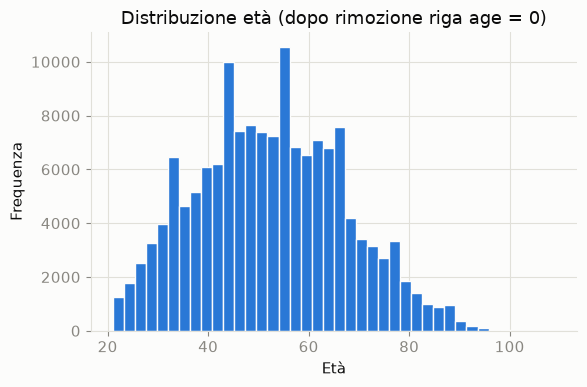

In [12]:
# Verifica già eseguita in §4 (rimozione anticipata, necessaria per l'imputazione per fascia d'età).
# La confermiamo qui sul dataset originale per completezza documentale.
raw_age = pd.read_csv(RAW_PATH, index_col=0)['age']
n_zero_age = (raw_age == 0).sum()
print(f"Righe con age = 0 nel dataset originale: {n_zero_age}")
print(f"Righe totali dopo la rimozione: {len(df):,}")

fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(df['age'], bins=40, color=COLOR_SEQ, edgecolor='#fcfcfb')
ax.set_title('Distribuzione età (dopo rimozione riga age = 0)')
ax.set_xlabel('Età')
ax.set_ylabel('Frequenza')
plt.tight_layout()
plt.show()

**Decisione:** una sola riga su 150.000 aveva `age = 0`, un valore impossibile per un richiedente di
credito. Trattandosi di un'unica osservazione, la rimuoviamo direttamente (non ha senso imputare
un'età plausibile per un singolo caso: la perdita di informazione è trascurabile, l'impatto di un
valore errato su modelli successivi potenzialmente no).

### 5.2 Valori sentinella (96 / 98) nelle colonne dei ritardi di pagamento

Le colonne `NumberOfTime30-59DaysPastDueNotWorse`, `NumberOfTime60-89DaysPastDueNotWorse` e
`NumberOfTimes90DaysLate` contano il numero di volte in cui un pagamento è stato in ritardo: valori
come 96 o 98 non sono ritardi reali (impossibili in una finestra di osservazione di 2 anni), ma codici
sentinella/placeholder noti in questo dataset.

In [13]:
delinq_cols = [
    'NumberOfTime30-59DaysPastDueNotWorse',
    'NumberOfTime60-89DaysPastDueNotWorse',
    'NumberOfTimes90DaysLate',
]

for col in delinq_cols:
    print(col)
    print(df[col].value_counts().sort_index(ascending=False).head(3))
    print()

sentinel_mask = (df[delinq_cols] >= 96).any(axis=1)
stesse_righe = (df.loc[sentinel_mask, delinq_cols] >= 96).all(axis=1).all()

print(f"Righe con valore sentinella (>=96): {sentinel_mask.sum()} ({sentinel_mask.mean() * 100:.2f}%)")
print(f"Sono le stesse righe su tutte e 3 le colonne: {stesse_righe}")
print(f"Tasso di insolvenza righe sentinella:  {df.loc[sentinel_mask, 'SeriousDlqin2yrs'].mean():.4f}")
print(f"Tasso di insolvenza resto del dataset: {df.loc[~sentinel_mask, 'SeriousDlqin2yrs'].mean():.4f}")

NumberOfTime30-59DaysPastDueNotWorse
NumberOfTime30-59DaysPastDueNotWorse
98    264
96      5
13      1
Name: count, dtype: int64

NumberOfTime60-89DaysPastDueNotWorse
NumberOfTime60-89DaysPastDueNotWorse
98    264
96      5
11      1
Name: count, dtype: int64

NumberOfTimes90DaysLate
NumberOfTimes90DaysLate
98    264
96      5
17      1
Name: count, dtype: int64

Righe con valore sentinella (>=96): 269 (0.18%)
Sono le stesse righe su tutte e 3 le colonne: True
Tasso di insolvenza righe sentinella:  0.5465


Tasso di insolvenza resto del dataset: 0.0660


**Osservazioni.** Sono **269 righe** (0,18% del dataset), le **stesse** su tutte e tre le colonne: quando
una è sentinella lo sono anche le altre due, il che suggerisce un unico blocco di record con un codice
di stato anomalo comune, non un errore casuale indipendente per colonna. Il tasso di insolvenza di
queste righe è **~54,6%**, contro **~6,6%** nel resto del dataset: un valore ottenuto per errore non
dovrebbe correlare così fortemente con il target, quindi il codice sentinella è probabilmente esso
stesso informativo (es. un segnale di stato di sofferenza già noto all'istituto).

**Decisione:** non eliminiamo queste righe (perderemmo un segnale forte, oltre a ~147 casi di insolvenza
reale su un totale di soli 10.026). Invece:

1. Creiamo un flag binario `flag_delinquenza_anomala` che cattura esplicitamente il segnale.
2. Limitiamo (*cap*) il valore numerico delle tre colonne al massimo valore realistico osservato in
   quella colonna (calcolato dinamicamente, escludendo le sentinelle), così i modelli successivi non
   vedono più magnitudini impossibili come 96-98.

In [14]:
df['flag_delinquenza_anomala'] = sentinel_mask.astype(int)

for col in delinq_cols:
    cap_value = df.loc[~sentinel_mask, col].max()
    n_capped = (df[col] >= 96).sum()
    df.loc[df[col] >= 96, col] = cap_value
    print(f"{col}: {n_capped} righe portate al cap = {cap_value}")

NumberOfTime30-59DaysPastDueNotWorse: 269 righe portate al cap = 13
NumberOfTime60-89DaysPastDueNotWorse: 269 righe portate al cap = 11
NumberOfTimes90DaysLate: 269 righe portate al cap = 17


### 5.3 `RevolvingUtilizationOfUnsecuredLines` e `DebtRatio`

Entrambe sono definite come rapporti (utilizzo delle linee di credito revolving rispetto al fido
concesso; rapporto rata/reddito) e dovrebbero avere un range contenuto, ma presentano code estreme.

In [15]:
for col in ['RevolvingUtilizationOfUnsecuredLines', 'DebtRatio']:
    print(f"--- {col} ---")
    print(df[col].describe())
    print(f"righe > 1: {(df[col] > 1).sum()}")
    print(f"righe > 1000: {(df[col] > 1000).sum()}")
    print(f"massimo: {df[col].max():,.1f}")
    print()

--- RevolvingUtilizationOfUnsecuredLines ---
count    149999.000000
mean          6.048472
std         249.756203
min           0.000000
25%           0.029867
50%           0.154176
75%           0.559044
max       50708.000000
Name: RevolvingUtilizationOfUnsecuredLines, dtype: float64
righe > 1: 3321
righe > 1000: 172
massimo: 50,708.0

--- DebtRatio ---
count    149999.000000
mean        353.007426
std        2037.825113
min           0.000000
25%           0.175074
50%           0.366503
75%           0.868257
max      329664.000000
Name: DebtRatio, dtype: float64
righe > 1: 35137
righe > 1000: 16892
massimo: 329,664.0



`RevolvingUtilizationOfUnsecuredLines` arriva a un massimo di ~50.708 (dovrebbe restare vicino a 1).
`DebtRatio` arriva a ~329.664. Prima di scegliere una soglia arbitraria, verifichiamo se le code
estreme di `DebtRatio` sono legate al reddito mancante o nullo, visto che è calcolato come rapporto
rispetto al reddito mensile.

In [16]:
extreme_dr = df['DebtRatio'] > 1000
income_missing_share = df.loc[extreme_dr, 'MonthlyIncome_mancante'].mean()
print(f"Righe con DebtRatio > 1000: {extreme_dr.sum()}")
print(f"...di cui con MonthlyIncome originariamente mancante: {income_missing_share * 100:.1f}%")

Righe con DebtRatio > 1000: 16892
...di cui con MonthlyIncome originariamente mancante: 94.1%


**Osservazioni.** Oltre il 94% delle righe con `DebtRatio` estremo aveva originariamente
`MonthlyIncome` mancante (o pari a zero): quando il reddito è nullo o assente, il rapporto
debito/reddito esplode matematicamente, quindi la coda estrema non è un insieme di errori
indipendenti ma un artefatto della formula applicato su un denominatore vicino a zero.

**Decisione:** applichiamo un **winsorizing al 99° percentile** a entrambe le colonne (limitiamo il
valore all'estremo superiore osservato nel 99% dei casi, calcolato sui dati, non un numero scelto a
priori). Interessa circa l'1% delle righe per colonna e rimuove la coda impossibile mantenendo
inalterata la stragrande maggioranza dei dati, inclusi i casi realistici di utilizzo oltre il 100%
(sovra-fido) o di debt ratio elevato ma plausibile.

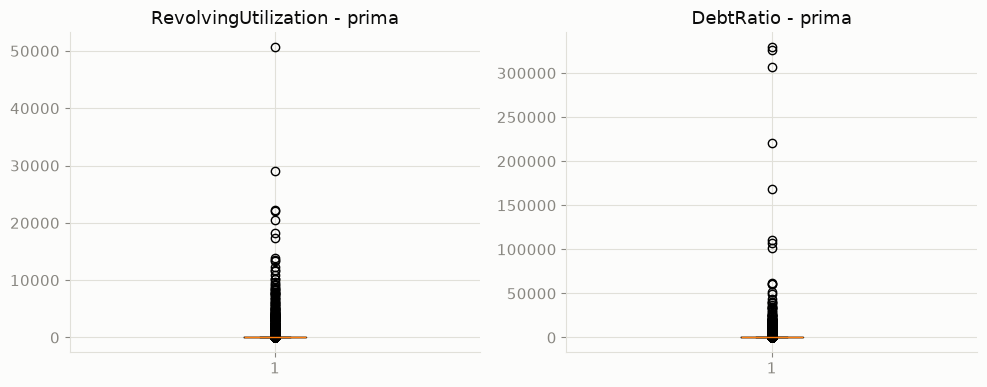

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].boxplot(df['RevolvingUtilizationOfUnsecuredLines'], vert=True)
axes[0].set_title('RevolvingUtilization - prima')
axes[1].boxplot(df['DebtRatio'], vert=True)
axes[1].set_title('DebtRatio - prima')
plt.tight_layout()
plt.show()

In [18]:
for col in ['RevolvingUtilizationOfUnsecuredLines', 'DebtRatio']:
    cap = df[col].quantile(0.99)
    n_capped = (df[col] > cap).sum()
    df[col] = df[col].clip(upper=cap)
    print(f"{col}: cap al 99° percentile = {cap:.3f}, righe modificate = {n_capped} ({n_capped / len(df) * 100:.2f}%)")

RevolvingUtilizationOfUnsecuredLines: cap al 99° percentile = 1.093, righe modificate = 1500 (1.00%)
DebtRatio: cap al 99° percentile = 4979.080, righe modificate = 1500 (1.00%)


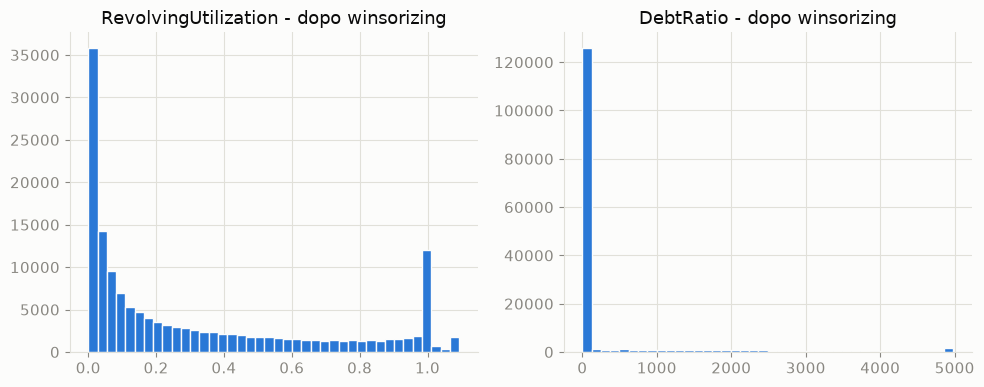

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(df['RevolvingUtilizationOfUnsecuredLines'], bins=40, color=COLOR_SEQ, edgecolor='#fcfcfb')
axes[0].set_title('RevolvingUtilization - dopo winsorizing')
axes[1].hist(df['DebtRatio'], bins=40, color=COLOR_SEQ, edgecolor='#fcfcfb')
axes[1].set_title('DebtRatio - dopo winsorizing')
plt.tight_layout()
plt.show()

## 6. Controllo finale e salvataggio

Riepilogo delle trasformazioni applicate al dataset:

| # | Intervento | Righe/colonne interessate |
|---|---|---|
| 1 | Rimozione riga con `age = 0` | 1 riga |
| 2 | Flag + imputazione `MonthlyIncome` (mediana per fascia d'età) | 29.731 righe (19,82%) |
| 3 | Flag + imputazione `NumberOfDependents` (0) | 3.924 righe (2,62%) |
| 4 | Flag `flag_delinquenza_anomala` + cap valori sentinella (96/98) | 269 righe |
| 5 | Winsorizing `RevolvingUtilizationOfUnsecuredLines` al 99° percentile | ~1% delle righe |
| 6 | Winsorizing `DebtRatio` al 99° percentile | ~1% delle righe |

Nuove colonne aggiunte: `MonthlyIncome_mancante`, `NumberOfDependents_mancante`, `flag_delinquenza_anomala`.

In [20]:
print("Valori mancanti residui nel dataset:", int(df.isnull().sum().sum()))
print(f"Dimensioni finali: {df.shape[0]:,} righe x {df.shape[1]} colonne")
df.describe().T

Valori mancanti residui nel dataset: 0
Dimensioni finali: 149,999 righe x 15 colonne


,count,mean,std,min,25%,50%,75%,max
SeriousDlqin2yrs,149999.0,0.066840,0.249746,0.0,0.000000,0.000000,0.000000,1.000000e+00
RevolvingUtilizationOfUnsecuredLines,149999.0,0.320491,0.352149,0.0,0.029867,0.154176,0.559044,1.092958e+00
age,149999.0,52.295555,14.771298,21.0,41.000000,52.000000,63.000000,1.090000e+02
NumberOfTime30-59DaysPastDueNotWorse,149999.0,0.268662,0.881604,0.0,0.000000,0.000000,0.000000,1.300000e+01
DebtRatio,149999.0,316.551377,906.966934,0.0,0.175074,0.366503,0.868257,4.979080e+03
MonthlyIncome,149999.0,6433.849172,12895.919029,0.0,3700.000000,5500.000000,7400.000000,3.008750e+06
NumberOfOpenCreditLinesAndLoans,149999.0,8.452776,5.145964,0.0,5.000000,8.000000,11.000000,5.800000e+01
NumberOfTimes90DaysLate,149999.0,0.120781,0.864393,0.0,0.000000,0.000000,0.000000,1.700000e+01
NumberRealEstateLoansOrLines,149999.0,1.018233,1.129772,0.0,0.000000,1.000000,2.000000,5.400000e+01
NumberOfTime60-89DaysPastDueNotWorse,149999.0,0.084434,0.568168,0.0,0.000000,0.000000,0.000000,1.100000e+01


In [21]:
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

df_out = df.drop(columns=['age_fascia'])
df_out.to_csv(PROCESSED_PATH, index=True)

print(f"Dataset pulito salvato in: {PROCESSED_PATH.relative_to(PROJECT_ROOT).as_posix()}")
print(f"Dimensioni salvate: {df_out.shape[0]:,} righe x {df_out.shape[1]} colonne")

Dataset pulito salvato in: data/processed/cs-training-clean.csv
Dimensioni salvate: 149,999 righe x 14 colonne


## Conclusioni

- Il dataset originale (150.000 righe) presenta uno squilibrio di classe marcato (6,68% di insolvenze),
  un errore isolato in `age`, un blocco di 269 record con codici sentinella nelle colonne di ritardo
  fortemente correlato al target, e code estreme in `RevolvingUtilizationOfUnsecuredLines`/`DebtRatio`
  legate soprattutto al reddito mancante.
- Ogni intervento di pulizia è stato scelto per **preservare il segnale predittivo** (flag informativi)
  invece di limitarsi a rimuovere le anomalie.
- Il dataset pulito (149.999 righe, con 3 nuove colonne indicatore) è salvato in
  `data/processed/cs-training-clean.csv` ed è il punto di partenza per il notebook
  `02_analisi_statistica`.